## SETUP

In [431]:
#import the necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import lightgbm as lgb
from pathlib import Path
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
import warnings
warnings.filterwarnings("ignore")

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

import mlflow
import mlflow.sklearn

from catboost import CatBoostRegressor
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.impute import SimpleImputer

In [432]:
PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data" / "processed"

In [433]:
MLFLOW_DB = (PROJECT_ROOT / 'mlflow.db').resolve()

mlflow.set_tracking_uri(f"sqlite:///{MLFLOW_DB.as_posix()}")
mlflow.set_experiment("GB_electricity_demand_forecasting")

<Experiment: artifact_location=('/Users/kwakye/Desktop/Github '
 'Projects/portfolio_project_one/gb-demand-imbalance-forecasting/notebooks/mlruns/2'), creation_time=1794220845604, effective_trace_archival_retention=None, experiment_id='2', last_update_time=1794220845604, lifecycle_stage='active', name='GB_electricity_demand_forecasting', tags={}, trace_location=None, workspace='default'>

In [434]:
def track_model(run_name,model,predictions,actuals,X_val,extra_params = None,tags =None):
    with mlflow.start_run(run_name= run_name):
        if hasattr(model,"named_steps"):
            estimator = model.named_steps['model']
        else:
            estimator = model


        mlflow.log_params(estimator.get_params())

        if extra_params:
            mlflow.log_params(extra_params)

        mae = mean_absolute_error(actuals,predictions)
        mlflow.log_metric("validation_mae", float(mae))
        mlflow.log_metric("validation_rows", len(actuals))
        

        mlflow.set_tags({"training_period": "2020-2024",
                         "validation_period": "2025",
                         "training_weather": "Historical actual weather",
                         "validation_weather": "ECMWF IFS 0.25 - 48h forecasts",})

        if tags:
            mlflow.set_tags(tags)

        mlflow.log_dict({"feature_names":X_val.columns.tolist(),
                         "feature_dtypes": {col:str(dtype) 
                                            for col,dtype in X_val.dtypes.items()}}
                                            ,"feature_schema.json")


        mlflow.sklearn.log_model(
            sk_model =model,
            name = "model",
            skops_trusted_types=[
            "collections.OrderedDict",
            "lightgbm.basic.Booster",
            "lightgbm.sklearn.LGBMRegressor",
            "catboost.core.CatBoostRegressor",
            "gb_demand_forecasting.models.catboost_ridge_blend.CatBoostRidgeBlend",
            "numpy.dtype"])

        print(f"Tracked: {run_name} | MAE: {mae:.2f} MW")
        

In [435]:
#load the demand and forecast datasets from parquet files
gb_demand = pd.read_parquet(DATA_DIR / "gb_demand_features.parquet")
df = gb_demand.copy()

In [436]:
actual_weather_cols = ["temperature_2m","relative_humidity_2m","precipitation",
                       "wind_speed_10m","shortwave_radiation"]

forecast_weather_cols = ["forecast_temperature_2m","forecast_relative_humidity_2m", "forecast_precipitation",
    "forecast_wind_speed_10m","forecast_shortwave_radiation"]

In [437]:
def correct_forecast_weather(data, lookback_days=60, delay_days=7):
    """
    Correct the forecast weather data by adjusting for historical biases.
    arguments:
    data: pd.DataFrame - DataFrame containing actual and forecast weather data.
    lookback_days: int - Number of days to look back for calculating historical biases.
    delay_days: int - Number of days to delay the forecast data for bias correction.
    returns:
    pd.DataFrame - DataFrame with corrected forecast weather data.
    """
    data = data.copy()

    # Keep observations with complete actual and forecast weather data
    weather_bias_data = data.dropna(subset=actual_weather_cols + forecast_weather_cols)

    # Create a complete calendar of dates
    calendar_dates = pd.date_range(data["local_date"].min(), data["local_date"].max(), freq="D")

    # Latest date allowed when calculating historical forecast errors
    cutoff_dates = data["local_date"] - pd.Timedelta(days=delay_days)

    # Calculate rolling historical totals
    def rolling_history_sum(values, dates):
        daily_totals = values.groupby(dates).sum().reindex(calendar_dates, fill_value=0)
        return daily_totals.rolling(lookback_days, min_periods=20).sum().reindex(cutoff_dates).to_numpy()

    # Count historical observations with complete weather data
    observation_count = rolling_history_sum(
        pd.Series(1.0, index=weather_bias_data.index), weather_bias_data["local_date"]
    )

    # Correct weather using average forecast errors
    for variable in ["temperature_2m", "relative_humidity_2m"]:
        average_bias = rolling_history_sum(
            weather_bias_data[f"forecast_{variable}"] - weather_bias_data[variable],
            weather_bias_data["local_date"]
        ) / observation_count

        data[f"forecast_{variable}"] -= np.nan_to_num(
            average_bias, nan=0.0, posinf=0.0, neginf=0.0
        )

   # Correct weather using historical actual-to-forecast ratios
    for variable in ["wind_speed_10m", "precipitation"]:
        correction_factor = (
            rolling_history_sum(weather_bias_data[variable], weather_bias_data["local_date"])
            / rolling_history_sum(weather_bias_data[f"forecast_{variable}"], weather_bias_data["local_date"])
        )

        data[f"forecast_{variable}"] *= np.nan_to_num(
            np.clip(correction_factor, 0.5, 2), nan=1
        )

    # Hour-specific correction for shortwave radiation
    variable = "shortwave_radiation"
    utc_hours = data.index.hour
    radiation_factors = np.ones(len(data))

    for hour in range(24):
        hourly_history = weather_bias_data[weather_bias_data.index.hour == hour]

        actual_total = rolling_history_sum(hourly_history[variable], hourly_history["local_date"])
        forecast_total = rolling_history_sum(
            hourly_history[f"forecast_{variable}"], hourly_history["local_date"]
        )

        radiation_factors = np.where(
            utc_hours == hour,
            np.where(forecast_total > 500, actual_total / np.where(forecast_total > 0, forecast_total, 1), 1),
            radiation_factors
        )

    data[f"forecast_{variable}"] *= np.clip(np.nan_to_num(radiation_factors, nan=1), 0.5, 2)

    return data


df = correct_forecast_weather(df)

In [438]:
def add_temperature_time_features(X):
    """
    Add features that capture the relationship between temperature and demand. 
    Adds heating degree days (hdd), cooling degree days (cdd),their interactions with wind speed 
    and the square of temperature. Also adds a day-of-week × settlement-period interaction feature.

    arguments:
    X: pd.DataFrame
    Returns:
    pd.DataFrame
    """
    X = X.copy()
    X["hdd"] = (15.5 - X["temperature_2m"]).clip(lower=0)
    X["hdd_x_wind"] = X["hdd"] * X["wind_speed_10m"]
    X["cdd"] = (X["temperature_2m"] - 20).clip(lower=0)
    X["temp2"] = X["temperature_2m"] ** 2

    # Day-of-week × settlement-period interaction
    X["dow_sp"] = (X["day_of_week"].astype(str)+ "_"
    + X["SETTLEMENT_PERIOD"].astype(str))
    return X


def add_holiday_period_feature(X, sp_cols):
    """
    Add interaction features between holiday flags and settlement period columns.
    arguments:
    X: pd.DataFrame
    sp_cols: list - List of settlement period columns to interact with holiday flags.
    Returns:
    pd.DataFrame
    """
    X = X.copy()
    # Only use flags that actually exist
    flags = [flag for flag in ["is_holiday", "xmas_period"] if flag in X.columns]
    for flag in flags:
        for c in sp_cols:
            X[f"{flag}_x_{c}"] = X[flag] * X[c]

    return X



def prepare_model_features(data, feature_cols, use_forecast_weather, actual_weather_cols,forecast_weather_cols):
    """
    Prepare the model features by selecting the appropriate columns based on whether to use forecast weather data or actual weather data.
    arguments:
    data: pd.DataFrame - DataFrame containing the features.
    feature_cols: list - List of feature column names to select.
    use_forecast_weather: bool - Flag indicating whether to use forecast weather data or actual weather data.
    actual_to_forecast_names: dict - Dictionary mapping actual weather column names to forecast weather column names.
    returns:
    pd.DataFrame - DataFrame containing the selected and renamed features.
    """
    actual_to_forecast_names = dict(zip(actual_weather_cols, forecast_weather_cols))
    forecast_to_actual_names = {v: k for k, v in actual_to_forecast_names.items()}

    selected_cols = [
        actual_to_forecast_names.get(c, c) if use_forecast_weather else c
        for c in feature_cols if c != "solar"
    ]

    X = data[selected_cols].rename(columns=forecast_to_actual_names)

    if "solar" in feature_cols:
        radiation_col = "forecast_shortwave_radiation" if use_forecast_weather else "shortwave_radiation"
        X["solar"] = data["solar_cap_D"] * data[radiation_col]

    return X


def linear_model_pipeline(cat_cols, model):
    """
    Create a pipeline for a linear model that includes one-hot encoding of categorical columns,
    scaling of features.
    arguments:
    cat_cols: list - List of categorical column names to be one-hot encoded.
    model: sklearn estimator - The linear model to be used in the pipeline.
    returns:
    sklearn.pipeline.Pipeline - A pipeline that preprocesses the data and fits the model.
    
    """
    preprocessor = ColumnTransformer(
        [("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), cat_cols)],
        remainder="passthrough")
    return Pipeline([("prep", preprocessor), ("scale", StandardScaler()), ("model", model)])



In [ ]:
#Train and Test Split
train = df[df.local_date < "2025-01-01"].copy()
val = df[(df.local_date >= "2025-01-01") & (df.local_date < "2026-01-01")].copy()
test = df[(df.local_date >= "2026-01-01") & (df.local_date < "2026-10-01")].copy()
y_train = train["ND"].copy()
y_val = val["ND"].copy()
y_test = test["ND"].copy()
benchmark = val[["elexon_forecast", "seasonal_naive"]]


## EXPERIMENT 1

In [440]:
# Experiment 1 — features
exp1_cols = ["SETTLEMENT_PERIOD","day_of_week","month","is_holiday",
             "temperature_2m","relative_humidity_2m","precipitation",
             "shortwave_radiation","wind_speed_10m",
             "lag_2d","lag_7d","d_solar_7", "d_wind_7","d_solar_base","d_wind_base",'emb_solar_fc','emb_wind_fc']
cat_1 = ["SETTLEMENT_PERIOD", "day_of_week", "month"]

In [441]:
X1_train = prepare_model_features(train, exp1_cols, False, actual_weather_cols, forecast_weather_cols)
X1_val = prepare_model_features(val, exp1_cols, True, actual_weather_cols, forecast_weather_cols)
model_1 = linear_model_pipeline(cat_1, LinearRegression())
model_1.fit(X1_train, y_train)
pred_1 = model_1.predict(X1_val)
print(f"Experiment 1: linear regression: {mean_absolute_error(y_val, pred_1):.0f} MW")

Experiment 1: linear regression: 1168 MW


In [442]:
track_model(run_name="Exp1_LinearRegression",model=model_1,
            predictions=pred_1,actuals=y_val,X_val=X1_val,
            tags={"model_family": "LinearRegression","experiment": "1"}
            )

Tracked: Exp1_LinearRegression | MAE: 1168.14 MW


In [443]:
X1b_train = add_temperature_time_features(prepare_model_features(train, exp1_cols, False, actual_weather_cols, forecast_weather_cols)).drop(columns="dow_sp")
X1b_val = add_temperature_time_features(prepare_model_features(val, exp1_cols, True, actual_weather_cols, forecast_weather_cols)).drop(columns="dow_sp")
model_1b = linear_model_pipeline(cat_1, LinearRegression()).fit(X1b_train, y_train)
pred_1b = model_1b.predict(X1b_val)
print(f"Experiment 1b: linear regression: {mean_absolute_error(y_val, pred_1b):.0f} MW")

Experiment 1b: linear regression: 1061 MW


In [444]:
track_model(
    run_name="Exp1b_LinearRegression",
    model=model_1b,
    predictions=pred_1b,
    actuals=y_val,
    X_val=X1b_val,
    tags={
        "model_family": "LinearRegression",
        "experiment": "1b",
        "feature_engineering": "temperature_time_interactions"
    }
)

Tracked: Exp1b_LinearRegression | MAE: 1061.09 MW


In [445]:
cat_1 = cat_1 + ["dow_sp"]
X1c_train = add_temperature_time_features(prepare_model_features(train, exp1_cols, False, actual_weather_cols, forecast_weather_cols))
X1c_val = add_temperature_time_features(prepare_model_features(val, exp1_cols, True, actual_weather_cols, forecast_weather_cols))
model_1c = linear_model_pipeline(cat_1, LinearRegression()).fit(X1c_train, y_train)
pred_1c = model_1c.predict(X1c_val)
print(f"Experiment 1c: linear regression: {mean_absolute_error(y_val, pred_1c):.0f} MW")

Experiment 1c: linear regression: 927 MW


In [446]:
track_model(
    run_name="Exp1c_LinearRegression",
    model=model_1c,
    predictions=pred_1c,
    actuals=y_val,
    X_val=X1c_val,
    tags={
        "model_family": "LinearRegression",
        "experiment": "1c",
        "feature_engineering": "temperature_time_interactions_and_dow_sp"
    }
)

Tracked: Exp1c_LinearRegression | MAE: 926.90 MW


# Experiment 2

In [447]:
#without holiday and xmas period features
X2_train = add_temperature_time_features(prepare_model_features(train, exp1_cols, False, actual_weather_cols, forecast_weather_cols))
X2_val = add_temperature_time_features(prepare_model_features(val, exp1_cols, True, actual_weather_cols, forecast_weather_cols))
model_2a = linear_model_pipeline(cat_1, Ridge(alpha=100)).fit(X2_train, y_train)
pred_2a = model_2a.predict(X2_val)
print(f"Experiment 2a: Ridge regression: {mean_absolute_error(y_val, pred_2a):.0f} MW")

Experiment 2a: Ridge regression: 929 MW


In [448]:
track_model(
    run_name="Exp2a_Ridge",
    model=model_2a,
    predictions=pred_2a,
    actuals=y_val,
    X_val=X2_val,
    tags={
        "model_family": "Ridge",
        "experiment": "2a",
        "prediction_type": "direct"
    }
)

Tracked: Exp2a_Ridge | MAE: 929.44 MW


In [449]:
exp2_cols = ["SETTLEMENT_PERIOD", "day_of_week", "month", "is_holiday",
             "temperature_2m", "relative_humidity_2m", "precipitation",
             "shortwave_radiation", "wind_speed_10m", "lag_2d", "lag_7d",
             "xmas_period", "day_before_holiday", "day_after_holiday",
             "prev_6weeks_lag_noholiday", "lag7d_minus_prev_6weeks","d_solar_7", "d_wind_7","d_solar_base","d_wind_base",'emb_solar_fc','emb_wind_fc']
cat_2 = ["SETTLEMENT_PERIOD", "day_of_week", "month", "dow_sp", "hol_sp"]

In [450]:
def add_holiday_period(X,holiday_col, period_col):
    """
    Add holiday period features to the DataFrame.
    arguments:
    X: pd.DataFrame - DataFrame containing the features.
    holiday_col: str - Name of the column indicating holidays.
    period_col: str - Name of the column indicating settlement periods.
    returns:
    pd.DataFrame - DataFrame with added holiday period features.   
    """
    X = X.copy()
    X["hol_sp"] = np.where(X[holiday_col] == 1, X[period_col], 0)
    return X

In [451]:
X2_train = add_temperature_time_features(prepare_model_features(train, exp2_cols, False, actual_weather_cols, forecast_weather_cols))
X2_train = add_holiday_period(X2_train, "is_holiday", "SETTLEMENT_PERIOD")
X2_val = add_temperature_time_features(prepare_model_features(val, exp2_cols, True, actual_weather_cols, forecast_weather_cols))
X2_val = add_holiday_period(X2_val, "is_holiday", "SETTLEMENT_PERIOD")

In [452]:
age_years = (train.index.max() - train.index).days / 365.25
weights = 0.5 ** age_years
normal_train = train["prev_6weeks_lag_noholiday"]
normal_val = val["prev_6weeks_lag_noholiday"].to_numpy()

model_2b = linear_model_pipeline(cat_2, Ridge(alpha=10))
model_2b.fit(X2_train, y_train - normal_train, model__sample_weight=weights)
pred_2 = model_2b.predict(X2_val) + normal_val
print(f"Experiment 2b: Ridge regression with holiday features: {mean_absolute_error(y_val, pred_2):.0f} MW")

Experiment 2b: Ridge regression with holiday features: 854 MW


In [453]:
track_model(
    run_name="Exp2b_Ridge_Residual",
    model=model_2b,
    predictions=pred_2,
    actuals=y_val,
    X_val=X2_val,
    extra_params={
        "recency_half_life_years": 1
    },
    tags={
        "model_family": "Ridge",
        "experiment": "2b",
        "prediction_type": "residual",
        "baseline": "prev_6weeks_lag_noholiday",
        "sample_weighting": "recency"
    }
)

Tracked: Exp2b_Ridge_Residual | MAE: 854.20 MW


In [454]:
ridge_results = {}

for alpha in [0.1, 1, 10, 100, 1000, 10000]:

    model = linear_model_pipeline(cat_2, Ridge(alpha=alpha))

    model.fit(
        X2_train,
        y_train - normal_train,
        model__sample_weight=weights
    )

    pred = model.predict(X2_val) + normal_val

    mae = mean_absolute_error(y_val, pred)

    ridge_results[alpha] = mae

    # Track each alpha in MLflow
    track_model(
        run_name=f"Exp2_Ridge_alpha_{alpha}",
        model=model,
        predictions=pred,
        actuals=y_val,
        X_val=X2_val,
        extra_params={
            "recency_half_life_years": 1
        },
        tags={
            "model_family": "Ridge",
            "experiment_type": "hyperparameter_search",
            "prediction_type": "residual",
            "baseline": "prev_6weeks_lag_noholiday"
        }
    )

Tracked: Exp2_Ridge_alpha_0.1 | MAE: 852.48 MW
Tracked: Exp2_Ridge_alpha_1 | MAE: 852.63 MW
Tracked: Exp2_Ridge_alpha_10 | MAE: 854.20 MW
Tracked: Exp2_Ridge_alpha_100 | MAE: 869.81 MW
Tracked: Exp2_Ridge_alpha_1000 | MAE: 946.02 MW
Tracked: Exp2_Ridge_alpha_10000 | MAE: 1135.27 MW


## EXPERIMENT 3

In [455]:
exp3_cols = ["SETTLEMENT_PERIOD", "day_of_week", "month", "is_holiday",
             "temperature_2m", "relative_humidity_2m", "precipitation",
             "shortwave_radiation", "wind_speed_10m", "lag_2d", "lag_7d",
             "xmas_period", "day_before_holiday", "day_after_holiday",
             "prev_6weeks_lag_noholiday", "lag7d_minus_prev_6weeks","d_solar_7", "d_wind_7","d_solar_base","d_wind_base",'emb_solar_fc','emb_wind_fc']

cat_2 = ["SETTLEMENT_PERIOD", "day_of_week", "month", "dow_sp", "hol_sp"]

In [456]:
X3_train = add_temperature_time_features(prepare_model_features(train, exp3_cols, False, actual_weather_cols, forecast_weather_cols))
X3_train = add_holiday_period(X3_train, "is_holiday", "SETTLEMENT_PERIOD")
X3_val = add_temperature_time_features(prepare_model_features(val, exp3_cols, True, actual_weather_cols, forecast_weather_cols))
X3_val = add_holiday_period(X3_val, "is_holiday", "SETTLEMENT_PERIOD")
X3_test = add_temperature_time_features(prepare_model_features(test, exp3_cols, True, actual_weather_cols, forecast_weather_cols))
X3_test = add_holiday_period(X3_test, "is_holiday", "SETTLEMENT_PERIOD")


for col in cat_2:
    X3_train[col] = X3_train[col].astype('category')
    X3_val[col] = X3_val[col].astype('category')
    X3_test[col] = X3_test[col].astype('category')

In [457]:
X3_train_a = X3_train.copy()
X3_val_a = X3_val.copy()

In [458]:
model_3 = lgb.LGBMRegressor(random_state=42)
model_3.fit(X3_train_a,y_train)
pred_3 = model_3.predict(X3_val_a)
print(f"Experiment 3: LightGBM: {mean_absolute_error(y_val, pred_3):.0f} MW")

Experiment 3: LightGBM: 879 MW


In [459]:
track_model(
    run_name="Exp3_LightGBM_Baseline",
    model=model_3,
    predictions=pred_3,
    actuals=y_val,
    X_val=X3_val_a,
    tags={
        "model_family": "LightGBM",
        "experiment": "3",
        "prediction_type": "direct",
        "experiment_type": "baseline"
    }
)

Tracked: Exp3_LightGBM_Baseline | MAE: 878.85 MW


lgbm_results = {}

for leaves in [3,5,7]:
    for rate in [0.1, 0.2]:
        for trees in [3000,3500,4000]:

            model = lgb.LGBMRegressor(
                num_leaves=leaves,
                learning_rate=rate,
                n_estimators=trees,
                random_state=42,
                verbosity=-1
            )

            model.fit(X3_train_a, y_train)
            pred = model.predict(X3_val_a)

            mae = mean_absolute_error(y_val, pred)
            lgbm_results[(leaves, rate, trees)] = mae

            print(
                f"LightGBM: leaves={leaves}, "
                f"rate={rate}, trees={trees}: {mae:.0f} MW"
            )

            # Track this configuration in MLflow
            track_model(
                run_name=f"Exp3_LGBM_L{leaves}_LR{rate}_T{trees}",
                model=model,
                predictions=pred,
                actuals=y_val,
                X_val=X3_val_a,
                tags={
                    "model_family": "LightGBM",
                    "experiment": "3",
                    "experiment_type": "hyperparameter_search"
                }
            )

In [460]:
model_3b = lgb.LGBMRegressor(random_state=42, num_leaves=3, learning_rate=0.1, n_estimators=3500, verbosity=-1)
model_3b.fit(X3_train_a, y_train-normal_train)
pred_3b = model_3b.predict(X3_val_a) + normal_val
print(f"Experiment 3b: LightGBM with historical baseline: {mean_absolute_error(y_val, pred_3b):.0f} MW")

Experiment 3b: LightGBM with historical baseline: 787 MW


In [461]:
track_model(
    run_name="Exp3b_LightGBM_Residual",
    model=model_3b,
    predictions=pred_3b,
    actuals=y_val,
    X_val=X3_val_a,
    tags={
        "model_family": "LightGBM",
        "experiment": "3b",
        "prediction_type": "residual",
        "baseline": "prev_6weeks_lag_noholiday"
    }
)

Tracked: Exp3b_LightGBM_Residual | MAE: 787.14 MW


In [462]:
weights = np.asarray(0.5 ** age_years)
model_3c = lgb.LGBMRegressor(random_state=42, num_leaves=3, learning_rate=0.1, n_estimators=3500, verbosity=-1)
model_3c.fit(X3_train_a, y_train,sample_weight= weights)
pred_3c = model_3c.predict(X3_val_a)
print(f"Experiment 3c: LightGBM with recency weights: {mean_absolute_error(y_val, pred_3c):.0f} MW")

Experiment 3c: LightGBM with recency weights: 776 MW


In [463]:
track_model(
    run_name="Exp3c_LightGBM_Recency",
    model=model_3c,
    predictions=pred_3c,
    actuals=y_val,
    X_val=X3_val_a,
    extra_params={
        "recency_half_life_years": 1
    },
    tags={
        "model_family": "LightGBM",
        "experiment": "3c",
        "prediction_type": "direct",
        "sample_weighting": "recency"
    }
)

Tracked: Exp3c_LightGBM_Recency | MAE: 776.34 MW


In [464]:
# Final independent evaluation using 2026
test_predictions = model_3c.predict(X3_test)
test_mae = mean_absolute_error(y_test, test_predictions)
test_mae

897.0081684633845

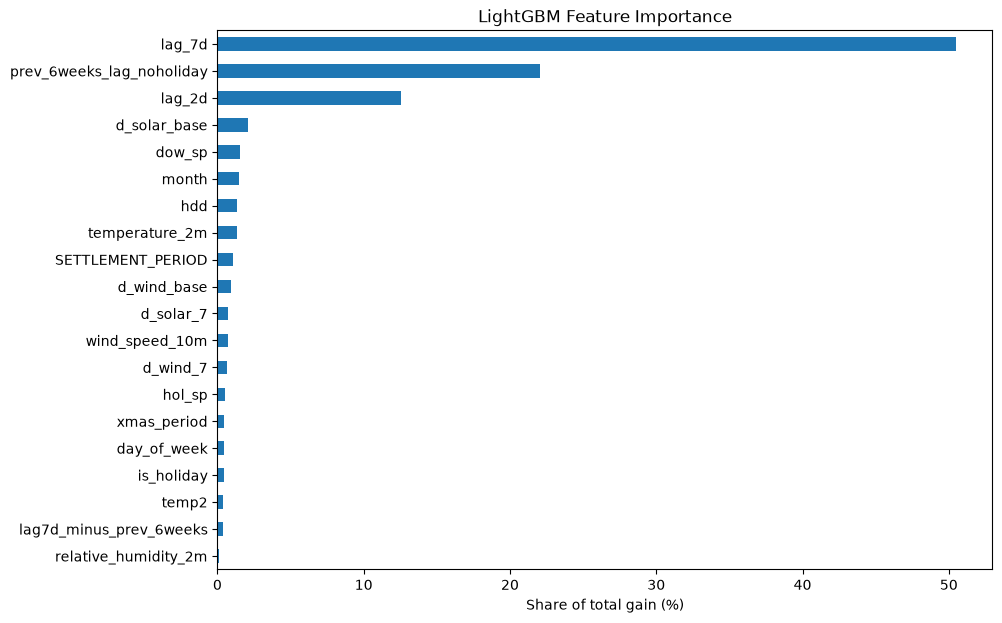

In [465]:
#check feature importance for the LightGBM model
importance = pd.Series(
    model_3c.booster_.feature_importance(importance_type="gain"),
    index=X3_train_a.columns).sort_values(ascending=False)

importance = 100 * importance / importance.sum()

importance.head(20).plot.barh(figsize=(10, 7))
plt.gca().invert_yaxis()
plt.xlabel("Share of total gain (%)")
plt.title("LightGBM Feature Importance")
plt.show()

# Experiment 4

In [466]:
import catboost as cb
from catboost import CatBoostRegressor

In [467]:
model_4 = CatBoostRegressor(iterations =5600,learning_rate=0.05,depth=4,
l2_leaf_reg= 3,rsm=0.7, random_seed=42,verbose=0)
model_4.fit(X3_train_a,y_train,sample_weight=weights,cat_features=cat_2)
pred_4 = model_4.predict(X3_val_a)
print(f"Experiment 4: CatBoost: {mean_absolute_error(y_val, pred_4):.0f} MW")

Experiment 4: CatBoost: 770 MW


In [468]:
track_model(
    run_name = "Exp4_CatBoost",
    model = model_4,
    predictions = pred_4,
    actuals = y_val,
    X_val = X3_val_a,
    extra_params = {
        "recency_half_life_years": 1
    },
    tags = {
        "model_family": "CatBoost",
        "experiment": "4",
        "prediction_type": "direct",
        "sample_weighting": "recency"
    })

Tracked: Exp4_CatBoost | MAE: 769.69 MW


In [469]:
CATBOOST_DEFAULTS = dict(iterations=5600, learning_rate=0.05, depth=4, l2_leaf_reg=3,
                         rsm=0.7, random_seed=42, verbose=0)


class CatBoostRidgeBlend(BaseEstimator, RegressorMixin):
    def __init__(self, cat_features, ridge_weight=0.25, ridge_alpha=10.0,
                 baseline_col="prev_6weeks_lag_noholiday", catboost_params=None):
        self.cat_features = cat_features
        self.ridge_weight = ridge_weight
        self.ridge_alpha = ridge_alpha
        self.baseline_col = baseline_col
        self.catboost_params = catboost_params

    def _as_text(self, X):
        X = X.copy()
        for column in self.cat_features:
            X[column] = X[column].astype(str)
        return X

    def fit(self, X, y, sample_weight=None):
        text = self._as_text(X)
        params = {**CATBOOST_DEFAULTS, **(self.catboost_params or {})}
        self.catboost_ = CatBoostRegressor(**params).fit(
            text, y, sample_weight=sample_weight, cat_features=list(self.cat_features))
        prep = ColumnTransformer(
            [("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False),
              list(self.cat_features))],
            remainder=SimpleImputer(strategy="median"))
        self.ridge_ = Pipeline([("prep", prep), ("scale", StandardScaler()),
                                ("model", Ridge(alpha=self.ridge_alpha))])
        self.ridge_.fit(text, np.asarray(y) - X[self.baseline_col].to_numpy(),
                        model__sample_weight=sample_weight)
        return self

    def predict(self, X):
        text = self._as_text(X)
        catboost = self.catboost_.predict(text)
        ridge = self.ridge_.predict(text) + X[self.baseline_col].to_numpy()
        return (1 - self.ridge_weight) * catboost + self.ridge_weight * ridge

In [470]:
blend = CatBoostRidgeBlend(cat_features=cat_2)
blend.fit(X3_train_a, y_train, sample_weight=weights)
pred_blend = blend.predict(X3_val_a)

In [471]:
track_model(
    run_name="Exp5_CatBoost_Ridge_Blend",
    model=blend,
    predictions=pred_blend,
    actuals=y_val,
    X_val=X3_val_a,
    extra_params={
        "recency_half_life_years": 1
    },
    tags={
        "model_family": "CatBoost_Ridge_Blend",
        "experiment": "5",
        "prediction_type": "direct_blend",
        "baseline": "prev_6weeks_lag_noholiday"
    }
)

MlflowException: The saved sklearn model references untrusted types. If you are sure loading these types is safe, set the 'skops_trusted_types' parameter when calling 'log_model' or 'save_model' to the list of trusted types. Root error: Untrusted types found in the file: ['__main__.CatBoostRidgeBlend'].

In [ ]:
from gb_demand_forecasting.models.catboost_ridge_blend import CatBoostRidgeBlend

blend_final = CatBoostRidgeBlend(cat_features=cat_2)

blend_final.fit(
    X_train,
    y_train,
    sample_weight=weights
)

pred_blend = blend_final.predict(X_test)

print("Model module:", type(blend_final).__module__)
print("2026 MAE:", mean_absolute_error(y_test, pred_blend))

Model module: gb_demand_forecasting.models.catboost_ridge_blend
2026 MAE: 824.7179135876582


In [ ]:
track_model(
    run_name="Exp6_CatBoost_Ridge_Blend",
    model=blend_final,
    predictions=pred_blend_2,
    actuals=y_test,
    X_val=X_test,
    extra_params={
        "recency_half_life_years": 1
    },
    tags={
        "model_family": "CatBoost_Ridge_Blend",
        "experiment": "6",
        "prediction_type": "direct_blend",
        "baseline": "prev_6weeks_lag_noholiday",
        "training_period": "2020-2025",
        "evaluation_period": "2026-01_to_2026-09",
        "model_source": "gb_demand_forecasting.models.catboost_ridge_blend",

    }
)

Tracked: Exp6_CatBoost_Ridge_Blend | MAE: 824.72 MW


In [473]:
model_uri = "models:/m-e458aded66c94add8b0121fffaf89bcf"

loaded_model = mlflow.sklearn.load_model(model_uri)
loaded_predictions = loaded_model.predict(X_test)
mae_loaded = mean_absolute_error(y_test, loaded_predictions)
print(f"Loaded model MAE on 2026 test set: {mae_loaded:.2f} MW")




Loaded model MAE on 2026 test set: 824.72 MW
